# COMP H2706: Fundamentals of AI & Data Science — Project
**Dataset:** Dataset1 (Even Student)  
**Classification Target:** `is_attack`  
**Regression Target:** `session_duration`

---
## CRISP-DM Framework
1. Business Understanding
2. Data Understanding & Exploration
3. Data Preparation
4. Modelling
5. Evaluation
6. Deployment / Conclusions

---

In [ ]:
# ── Imports ──────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, cross_validate
)
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    mean_squared_error, mean_absolute_error, r2_score
)

# Classification models
from sklearn.naive_bayes import ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Regression model
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

print('All libraries imported successfully.')

All libraries imported successfully.


---
## 1. Business Understanding

**Context:**  
A financial organisation is experiencing costly cyberattacks on its network infrastructure. As a data scientist, the goal is to analyse network session data to detect malicious traffic (`is_attack`) and understand behavioural patterns of sessions (predict `session_duration`).

**Objectives:**
- **Classification:** Predict whether a network session is an `Attack` or `Benign` using Naïve Bayes and Decision Tree classifiers.
- **Regression:** Predict the continuous `session_duration` of a session using Linear Regression and a Decision Tree Regressor.

**Success Criteria:**  
A well-performing classifier should achieve high recall for attacks (minimise false negatives — missing an attack is far more costly than a false alarm).

---

## 2. Data Understanding & Exploration

In [ ]:
# ── Load Data ──
df = pd.read_csv('/content/Dataset1_even_students.csv')
df.head()

,session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,session_duration,is_attack
0,S000000,TCP,IoT,On,APAC,1,0,3688.587042,7658.783289,184.351121,2,SYN,143,1,-58.159386,guest,0.632684,60.122861,Benign
1,S000001,ICMP,Server,Off,EU,1,2,4200.249009,7473.548707,127.567880,5,SYN-ACK,25,0,-61.394428,guest,0.665009,88.064962,Attack
2,S000002,TCP,Server,Off,APAC,1,0,5681.503452,6941.575921,206.334163,3,SYN,3389,1,-60.409574,user,0.024022,91.460489,Benign
3,S000003,ICMP,Server,On,US,1,0,7234.103007,10003.414511,106.159532,7,SYN-ACK,21,3,-49.082725,user,0.388327,92.349695,Benign
4,S000004,Udp,Workstation,Off,ME,1,0,5798.763455,7768.487288,116.326988,1,FIN,143,0,-56.260717,user,0.266618,91.778194,Benign


In [ ]:
# ── Basic Info ──
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   session_id        6000 non-null   object 
 1   protocol          5580 non-null   object 
 2   device_type       6000 non-null   object 
 3   vpn_status        6000 non-null   object 
 4   region            6000 non-null   object 
 5   login_attempts    6000 non-null   int64  
 6   failed_logins     6000 non-null   int64  
 7   bytes_sent        6000 non-null   float64
 8   bytes_received    5580 non-null   float64
 9   packet_rate       6000 non-null   float64
 10  connection_count  6000 non-null   int64  
 11  tcp_flags         6000 non-null   object 
 12  port_number       6000 non-null   int64  
 13  session_retries   6000 non-null   int64  
 14  signal_strength   5580 non-null   float64
 15  privilege_level   6000 non-null   object 
 16  anomaly_score     6000 non-null   float64


In [ ]:
# ── Descriptive Statistics ──
df[['failed_logins', 'anomaly_score', 'session_duration', 'bytes_sent', 'bytes_received']].describe()

,failed_logins,anomaly_score,session_duration,bytes_sent,bytes_received
count,6000.000000,6000.000000,6000.000000,6000.000000,5580.000000
mean,1.020667,0.283358,92.914416,5275.753584,5981.881281
std,1.004527,0.159846,16.595032,3132.622483,1994.673822
min,0.000000,0.002210,32.736351,100.000000,100.000000
25%,0.000000,0.157360,81.428235,4009.308961,4662.928544
50%,1.000000,0.260576,92.878546,5013.713497,5992.395457
75%,2.000000,0.389571,104.194079,6060.269321,7333.109710
max,7.000000,0.824099,156.431365,48743.941649,13019.206996


In [ ]:
# ── Descriptive Statistics ──
for col in ['protocol', 'vpn_status', 'is_attack']:
    print(col)
    print(df[col].value_counts(dropna=False))
    print("\n")

protocol
protocol
TCP     2532
UDP     1378
tcp      572
Udp      557
ICMP     541
NaN      420
Name: count, dtype: int64


vpn_status
vpn_status
Off    4184
On     1816
Name: count, dtype: int64


is_attack
is_attack
Benign    4481
Attack    1519
Name: count, dtype: int64




**Data Quality Issue Found:** The `protocol` column contains case-inconsistent labels: `'TCP'` and `'tcp'`, `'UDP'` and `'Udp'` refer to the same protocols. These must be standardised before modelling.

In [ ]:
# ── Descriptive Statistics ──
df[['protocol', 'vpn_status', 'is_attack']].describe()

,protocol,vpn_status,is_attack
count,5580,6000,6000
unique,5,2,2
top,TCP,Off,Benign
freq,2532,4184,4481


In [ ]:
# ── Check missing values ──
print('Missing values per column:')
missing = df.isnull().sum()
pct     = (missing / len(df) * 100).round(1)
print(pd.DataFrame({'Count': missing, '%': pct}))

Missing values per column:
                  Count    %
session_id            0  0.0
protocol            420  7.0
device_type           0  0.0
vpn_status            0  0.0
region                0  0.0
login_attempts        0  0.0
failed_logins         0  0.0
bytes_sent            0  0.0
bytes_received      420  7.0
packet_rate           0  0.0
connection_count      0  0.0
tcp_flags             0  0.0
port_number           0  0.0
session_retries       0  0.0
signal_strength     420  7.0
privilege_level       0  0.0
anomaly_score         0  0.0
session_duration      0  0.0
is_attack             0  0.0


In [ ]:
# ── Class Balance ──
print('is_attack distribution:\n')

print(df['is_attack'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')

is_attack distribution:

is_attack
Benign    74.7%
Attack    25.3%
Name: proportion, dtype: object


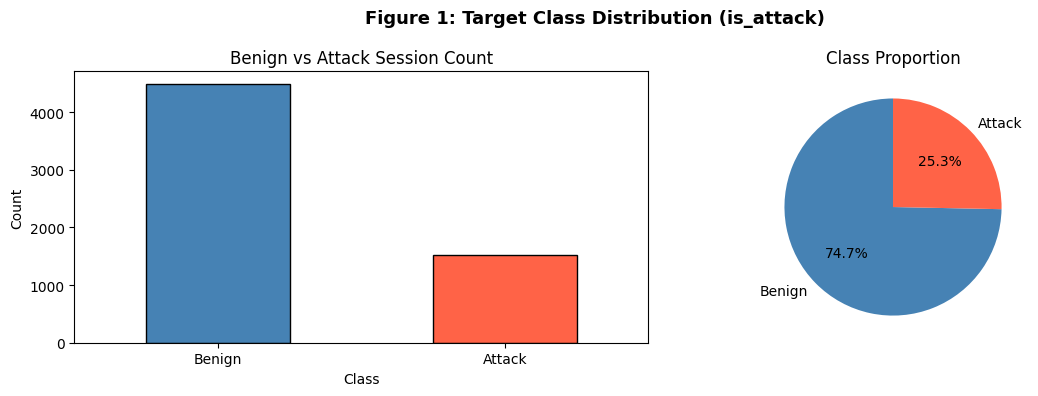

In [ ]:
# ── Visualisation 1: Class Distribution ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count bar
df['is_attack'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'tomato'],
                                     edgecolor='black')
axes[0].set_title('Benign vs Attack Session Count')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
axes[0].tick_params(rotation=0)

# Pie chart
df['is_attack'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%',
                                     colors=['steelblue', 'tomato'], startangle=90)
axes[1].set_title('Class Proportion')
axes[1].set_ylabel('')

plt.suptitle('Figure 1: Target Class Distribution (is_attack)', fontsize=13, fontweight='bold')
plt.tight_layout()

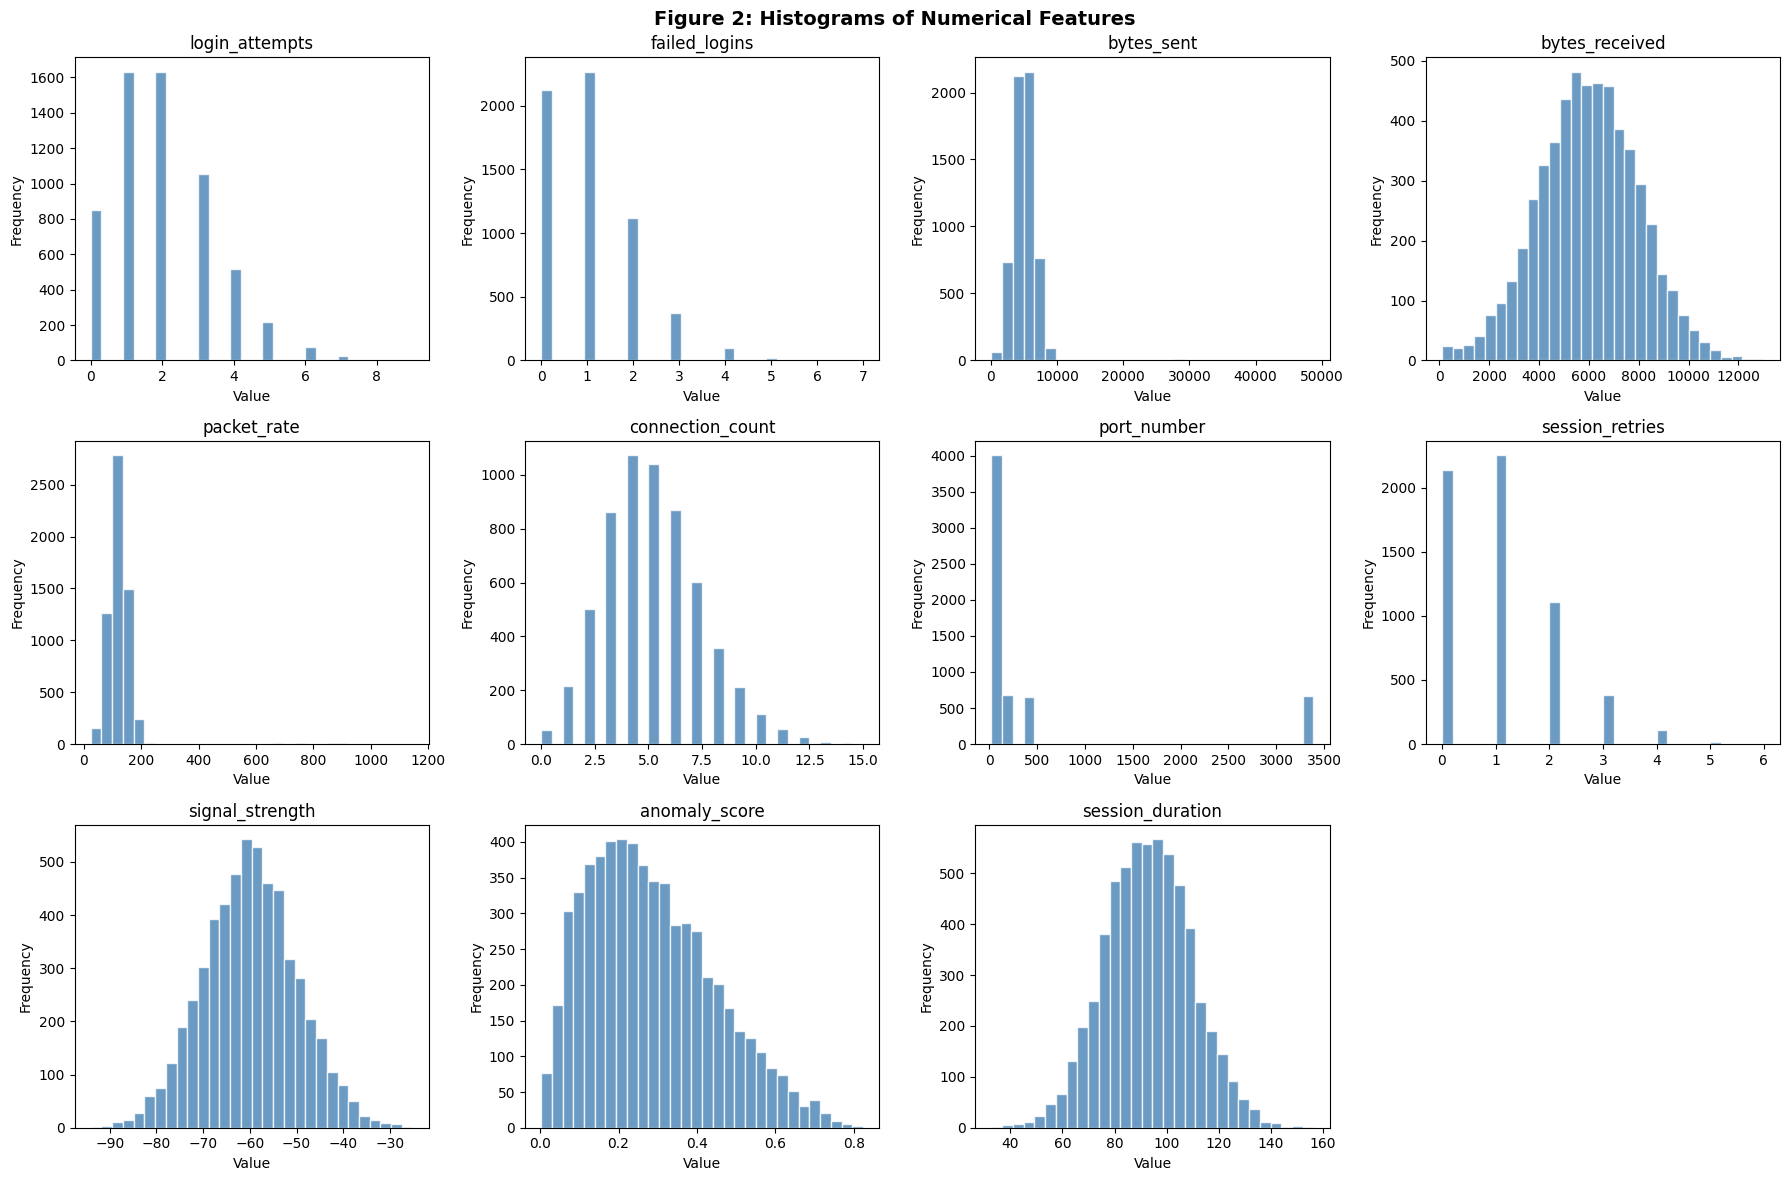

In [ ]:
# ── Visualisation 2: Numerical Feature Distributions ──
num_cols = ['login_attempts', 'failed_logins', 'bytes_sent', 'bytes_received',
            'packet_rate', 'connection_count', 'port_number', 'session_retries',
            'signal_strength', 'anomaly_score', 'session_duration']

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i].set_title(col)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Hide the unused 12th subplot
axes[-1].set_visible(False)

plt.suptitle('Figure 2: Histograms of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()

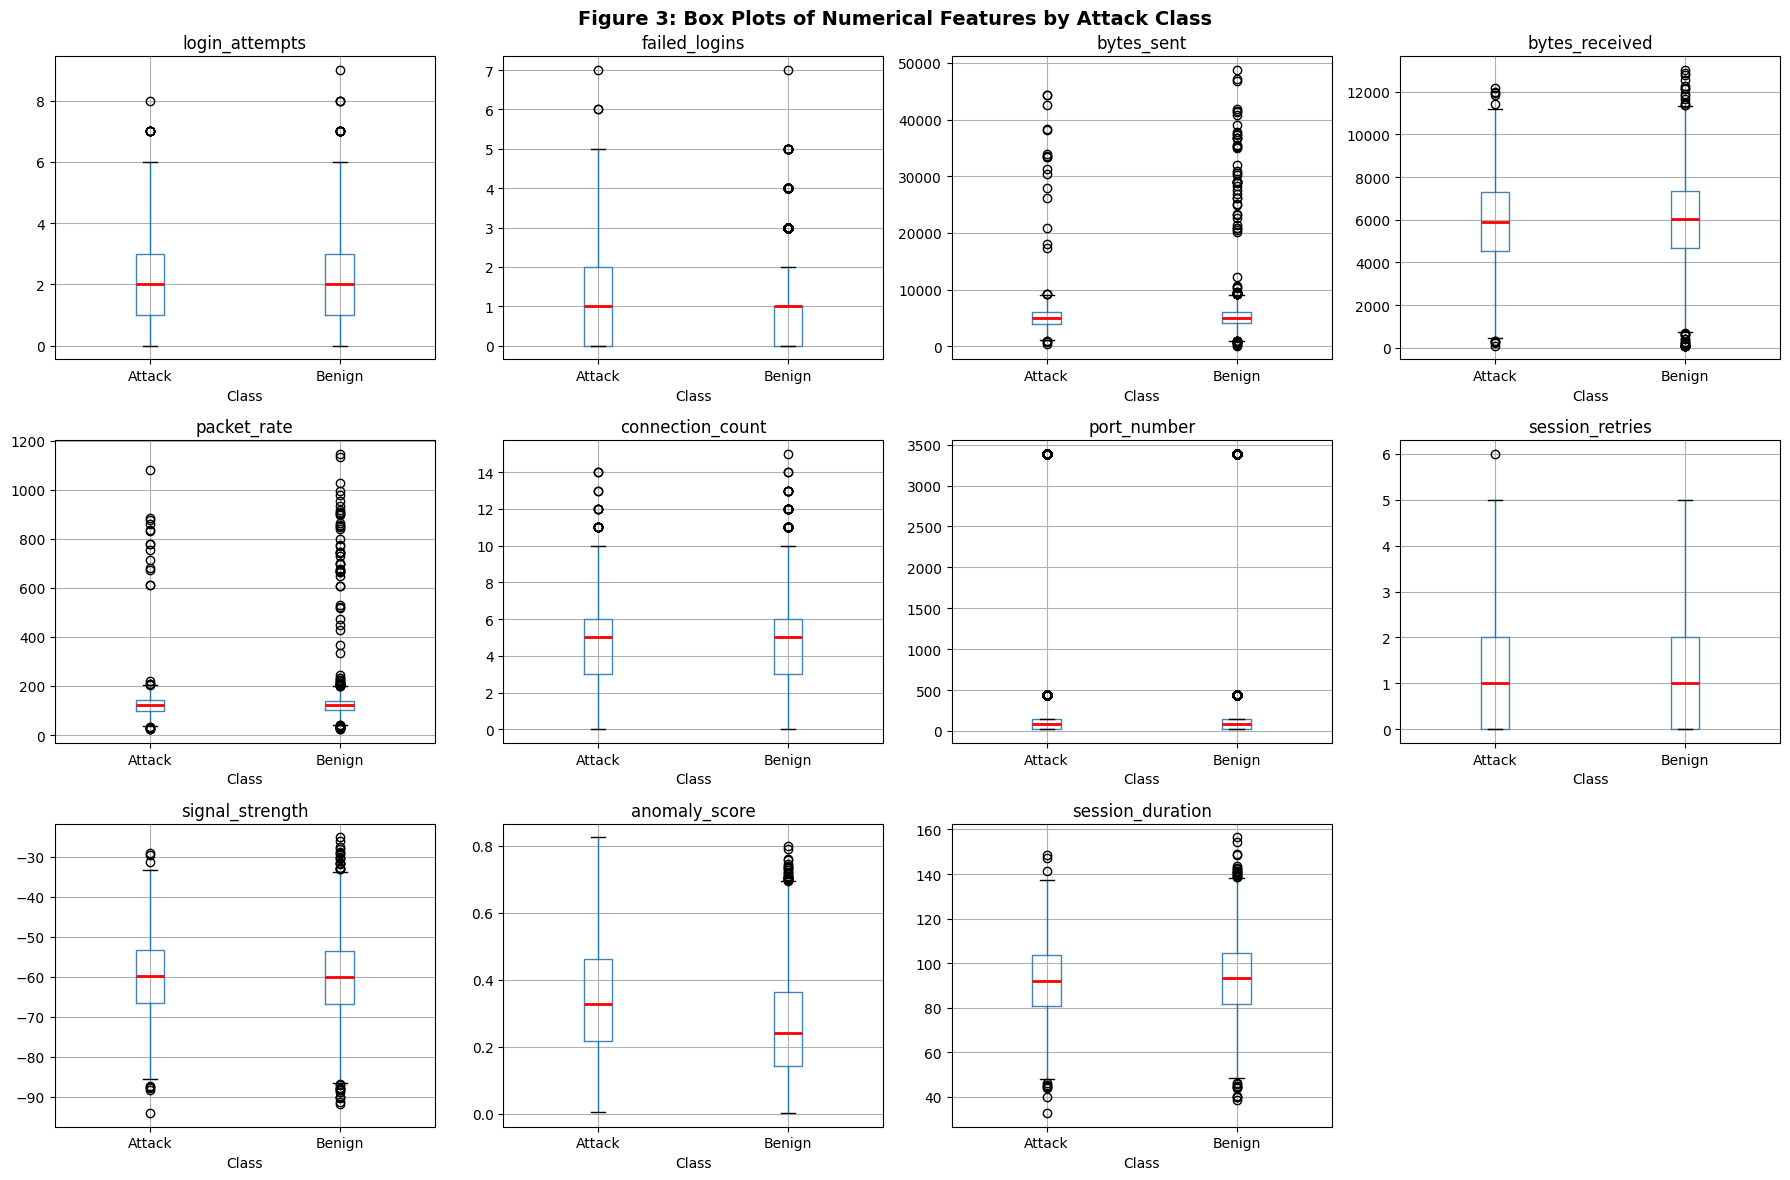

In [ ]:
# ── Visualisation 3: Box Plots — Numerical Features by Attack Class ──
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df.boxplot(column=col, by='is_attack', ax=axes[i],
               boxprops=dict(color='steelblue'),
               medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(col)
    axes[i].set_xlabel('Class')

axes[-1].set_visible(False)
plt.suptitle('Figure 3: Box Plots of Numerical Features by Attack Class', fontsize=14, fontweight='bold')
plt.tight_layout()

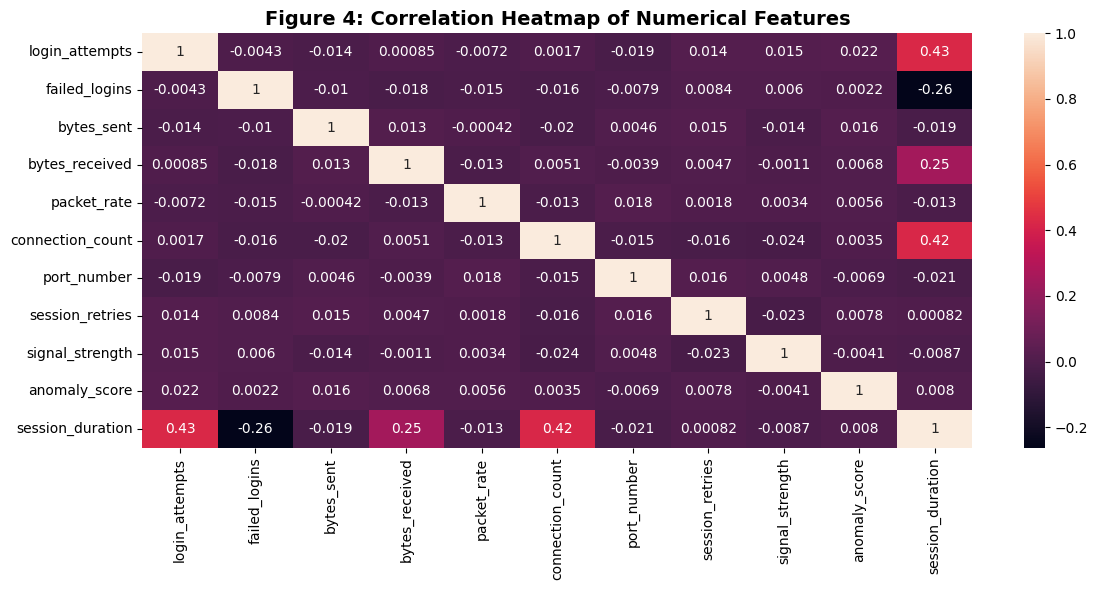

In [ ]:
# ── Visualisation 4: Correlation Heatmap ──
plt.figure(figsize=(12,6))
sns.heatmap(df.drop('session_id', axis=1).corr(numeric_only=True), annot=True)
plt.title('Figure 4: Correlation Heatmap of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()

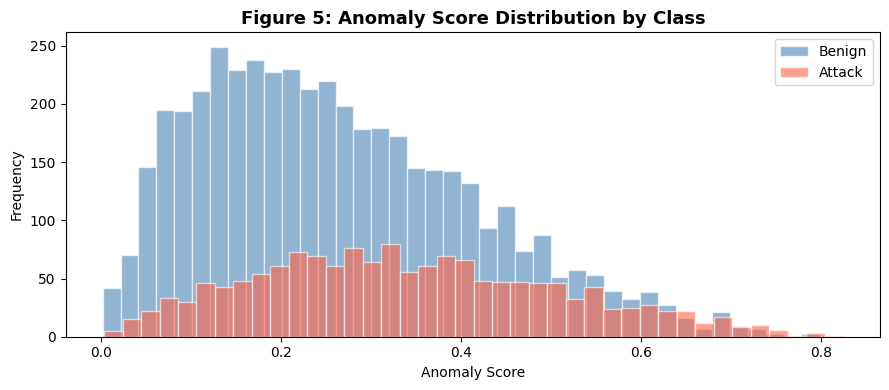

In [ ]:
# ── Visualisation 5: Anomaly Score Distribution by Class ──
fig, ax = plt.subplots(figsize=(9, 4))
for label, colour in [('Benign', 'steelblue'), ('Attack', 'tomato')]:
    subset = df[df['is_attack'] == label]['anomaly_score']
    ax.hist(subset, bins=40, alpha=0.6, color=colour, label=label, edgecolor='white')
ax.set_title('Figure 5: Anomaly Score Distribution by Class', fontsize=13, fontweight='bold')
ax.set_xlabel('Anomaly Score')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()

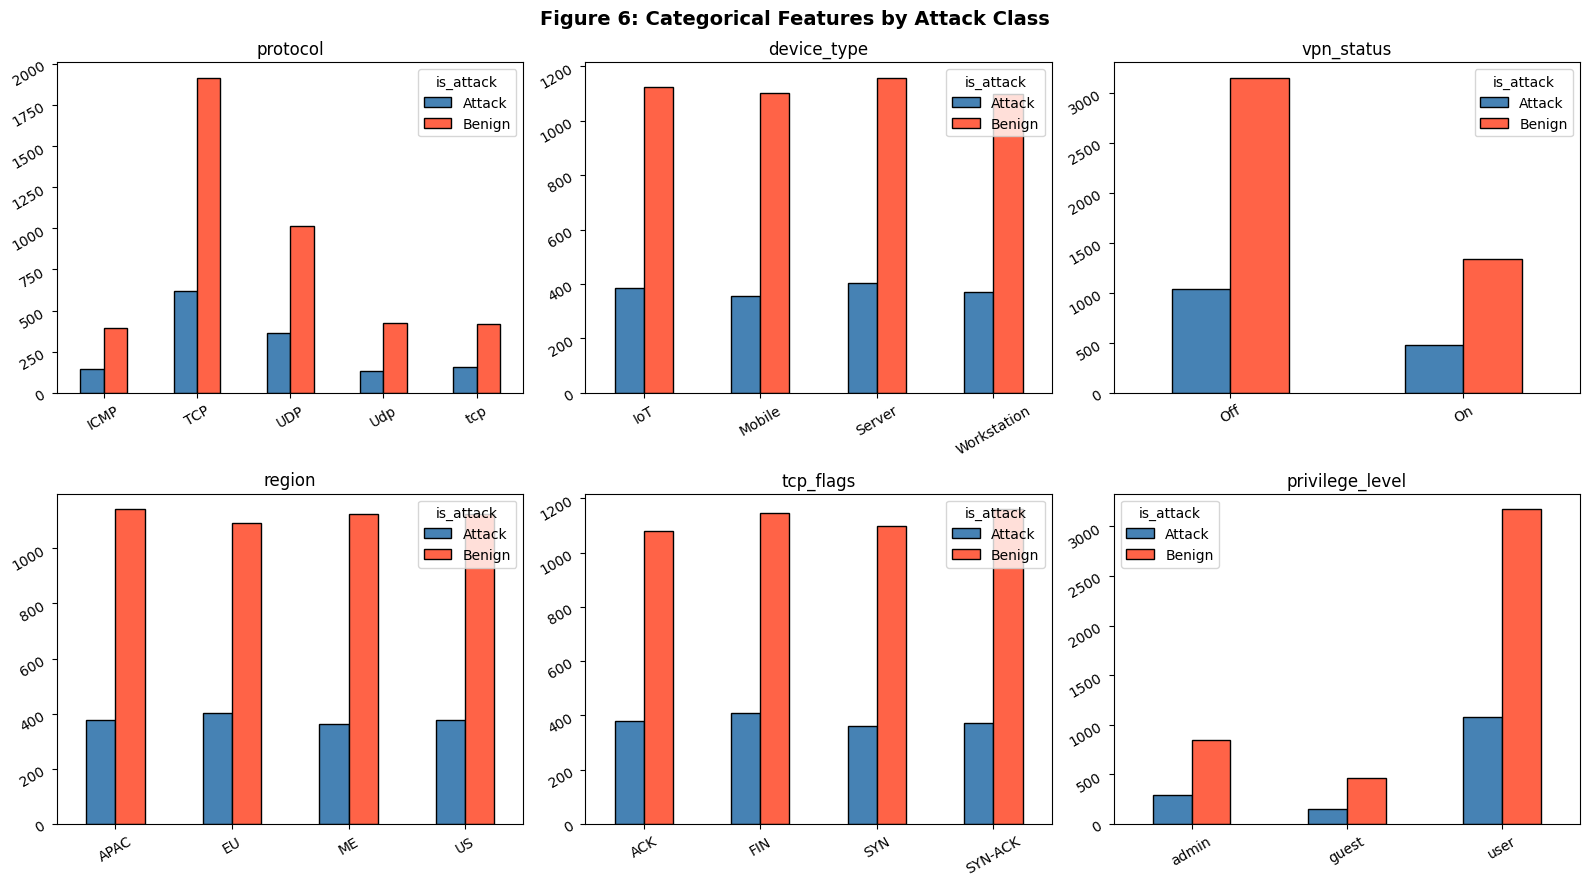

In [ ]:
# ── Visualisation 6: Categorical Feature Distributions ──
cat_cols = ['protocol', 'device_type', 'vpn_status', 'region', 'tcp_flags', 'privilege_level']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    counts = df.groupby([col, 'is_attack']).size().unstack(fill_value=0)
    counts.plot(kind='bar', ax=axes[i], color=['steelblue', 'tomato'], edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(rotation=30)
    axes[i].legend(title='is_attack')

plt.suptitle('Figure 6: Categorical Features by Attack Class', fontsize=14, fontweight='bold')
plt.tight_layout()

---
## 3. Data Preparation

In [ ]:
# ── 3.1 Copy & Drop Irrelevant Feature ──
data = df.copy()

# session_id is a unique identifier — not a predictive feature
data.drop(columns=['session_id'], inplace=True)

In [ ]:
# ── 3.2 Fix Inconsistent Protocol Values ──
# Standardise to uppercase to unify 'tcp'/'TCP', 'Udp'/'UDP'
data['protocol'] = data['protocol'].str.upper()
print('Protocol values after normalisation:')
print(data['protocol'].value_counts(dropna=False))

Protocol values after normalisation:
protocol
TCP     3104
UDP     1935
ICMP     541
NaN      420
Name: count, dtype: int64


In [ ]:
# ── 3.3 Handle Missing Values ──
cat_imputer = SimpleImputer(strategy='most_frequent')
data['protocol'] = cat_imputer.fit_transform(data[['protocol']]).ravel()

num_imputer = SimpleImputer(strategy='median')
data[['bytes_received', 'signal_strength']] = num_imputer.fit_transform(
    data[['bytes_received', 'signal_strength']]
)

print('Missing values after imputation:')
print(data.isnull().sum())

Missing values after imputation:
protocol            0
device_type         0
vpn_status          0
region              0
login_attempts      0
failed_logins       0
bytes_sent          0
bytes_received      0
packet_rate         0
connection_count    0
tcp_flags           0
port_number         0
session_retries     0
signal_strength     0
privilege_level     0
anomaly_score       0
session_duration    0
is_attack           0
dtype: int64


In [ ]:
# ── 3.4 Feature Engineering ──
# Feature 1: bytes_ratio
data['bytes_ratio'] = data['bytes_sent'] / (data['bytes_received'] + 1)

# Feature 2: login_failure_rate
data['login_failure_rate'] = data['failed_logins'] / (data['login_attempts'] + 1)

print('New features added: bytes_ratio, login_failure_rate')
data[['bytes_ratio', 'login_failure_rate']].describe()

New features added: bytes_ratio, login_failure_rate


,bytes_ratio,login_failure_rate
count,6000.000000,6000.000000
mean,1.138640,0.446977
std,2.374157,0.570549
min,0.027900,0.000000
25%,0.625924,0.000000
50%,0.843555,0.333333
75%,1.140435,0.666667
max,64.883211,6.000000


In [ ]:
# ── 3.5 Encode Categorical Features ──
label_cols = ['protocol', 'device_type', 'vpn_status', 'region', 'tcp_flags', 'privilege_level']

le = LabelEncoder()
for col in label_cols:
    data[col] = le.fit_transform(data[col].astype(str))

# Encode target: Attack=1, Benign=0
data['is_attack'] = le.fit_transform(data['is_attack'])
print('Unique is_attack values after encoding:', data['is_attack'].unique())
print('Encoding: Attack=1, Benign=0')
data[label_cols].head()

Unique is_attack values after encoding: [1 0]
Encoding: Attack=1, Benign=0


,protocol,device_type,vpn_status,region,tcp_flags,privilege_level
0,1,0,1,0,2,1
1,0,2,0,1,3,1
2,1,2,0,0,2,2
3,0,2,1,3,3,2
4,2,3,0,2,1,2


In [ ]:
# ── 3.6 Define Feature Sets & Targets ──
TARGET_CLASS = 'is_attack'
TARGET_REG   = 'session_duration'

# For classification — drop regression target
X_cls = data.drop(columns=[TARGET_CLASS, TARGET_REG])
y_cls = data[TARGET_CLASS]

# For regression — drop classification target
X_reg = data.drop(columns=[TARGET_CLASS, TARGET_REG])
y_reg = data[TARGET_REG]

print(f'Classification features: {X_cls.shape[1]}')
print(f'Regression features:     {X_reg.shape[1]}')

Classification features: 18
Regression features:     18


In [ ]:
# ── 3.7 Train / Test Split (70/30, stratified) ──
X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls, y_cls, test_size=0.30, random_state=42, stratify=y_cls
)

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.30, random_state=42
)

print(f'Classification — Train: {X_cls_train.shape[0]}, Test: {X_cls_test.shape[0]}')
print(f'Regression     — Train: {X_reg_train.shape[0]}, Test: {X_reg_test.shape[0]}')

Classification — Train: 4200, Test: 1800
Regression     — Train: 4200, Test: 1800


In [ ]:
# ── 3.8 Feature Scaling (for KNN / Regression) ──
scaler = StandardScaler()
X_cls_train_sc = scaler.fit_transform(X_cls_train)
X_cls_test_sc  = scaler.transform(X_cls_test)

X_reg_train_sc = scaler.fit_transform(X_reg_train)
X_reg_test_sc  = scaler.transform(X_reg_test)

# Separate scaling for ComplementNB, which requires non-negative features.
# MinMaxScaler scales features to a given range, typically [0, 1].
from sklearn.preprocessing import MinMaxScaler
minmax_scaler_nb = MinMaxScaler()
X_cls_train_nb = minmax_scaler_nb.fit_transform(X_cls_train)
X_cls_test_nb  = minmax_scaler_nb.transform(X_cls_test)

print('Scaling applied. Data is now ready for all models.')

Scaling applied. Data is now ready for all models.


In [ ]:
# Convert scaled classification data back to DataFrame
X_cls_train_norm_df = pd.DataFrame(
    X_cls_train_nb,
    columns=X_cls.columns
)

print("Before normalisation (min/max):")
display(X_cls_train.describe().loc[['min', 'max']])

print("After Min–Max normalisation (min/max):")
display(X_cls_train_norm_df.describe().loc[['min', 'max']])

Before normalisation (min/max):


,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,bytes_ratio,login_failure_rate
min,0.0,0.0,0.0,0.0,0.0,0.0,100.000000,100.000000,25.113174,0.0,0.0,21.0,0.0,-94.085793,0.0,0.002210,0.027900,0.0
max,2.0,3.0,1.0,3.0,9.0,7.0,48743.941649,13019.206996,1147.060032,15.0,3.0,3389.0,6.0,-25.139054,2.0,0.824099,57.183719,6.0


After Min–Max normalisation (min/max):


,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,bytes_ratio,login_failure_rate
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


---
## 4. Modelling

### 4A. Classification — Naïve Bayes (ComplementNB)

In [ ]:
# ── 4A.1 Baseline Naïve Bayes ──
nb_baseline = ComplementNB(alpha=0, force_alpha=True, norm=False)
nb_baseline.fit(X_cls_train_nb, y_cls_train)

y_pred_nb_baseline = nb_baseline.predict(X_cls_test_nb)

print('=== Baseline Naïve Bayes (alpha=0, norm=False) ===')
print(classification_report(y_cls_test, y_pred_nb_baseline,
                             target_names=['Benign', 'Attack']))

=== Baseline Naïve Bayes (alpha=0, norm=False) ===
              precision    recall  f1-score   support

      Benign       0.32      0.56      0.41       456
      Attack       0.80      0.59      0.68      1344

    accuracy                           0.59      1800
   macro avg       0.56      0.58      0.54      1800
weighted avg       0.68      0.59      0.61      1800



In [ ]:
# ── Train vs Test Accuracy — Baseline NB ──
train_pred_nb_bl = nb_baseline.predict(X_cls_train_nb)
print(f'Baseline NB | Train Acc: {accuracy_score(y_cls_train, train_pred_nb_bl):.4f}  '
      f'Test Acc: {accuracy_score(y_cls_test, y_pred_nb_baseline):.4f}')

Baseline NB | Train Acc: 0.5983  Test Acc: 0.5856


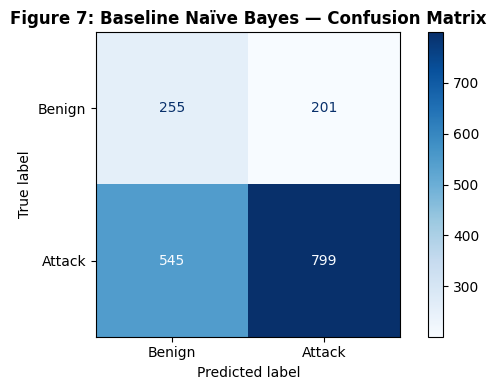

In [ ]:
# ── Confusion Matrix — Baseline NB ──
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_cls_test, y_pred_nb_baseline,
    display_labels=['Benign', 'Attack'], cmap='Blues', ax=ax
)
ax.set_title('Figure 7: Baseline Naïve Bayes — Confusion Matrix', fontweight='bold')
plt.tight_layout()

In [ ]:
# ── 4A.3 GridSearchCV — 5-Fold ──
param_grid_nb = {
    'alpha': [0.01, 0.1, 0.5, 1.0, 2.0, 10.0],
    'norm':  [True, False]
}

gs_nb_5 = GridSearchCV(
    ComplementNB(), param_grid_nb, cv=5,
    scoring='accuracy', return_train_score=True, n_jobs=-1
)
gs_nb_5.fit(X_cls_train_nb, y_cls_train)

print('Best params (5-fold):', gs_nb_5.best_params_)
print(f'Best CV accuracy:     {gs_nb_5.best_score_:.4f}')

Best params (5-fold): {'alpha': 10.0, 'norm': True}
Best CV accuracy:     0.7460


In [ ]:
# ── 4A.4 GridSearchCV — Stratified 10-Fold ──
gs_nb_10 = GridSearchCV(
    estimator=ComplementNB(),
    param_grid=param_grid_nb,
    cv=StratifiedKFold(10),
    scoring='accuracy',
    n_jobs=-1
)
gs_nb_10.fit(X_cls_train_nb, y_cls_train)

print('Best params (Stratified 10-fold):', gs_nb_10.best_params_)
print(f'Best CV accuracy:                 {gs_nb_10.best_score_:.4f}')

Best params (Stratified 10-fold): {'alpha': 10.0, 'norm': True}
Best CV accuracy:                 0.7460


In [ ]:
# ── 4A.5 Evaluate Best NB Model on Test Set ──
nb_best = gs_nb_10.best_estimator_
y_pred_nb_best = nb_best.predict(X_cls_test_nb)

print(f'=== Best Naïve Bayes {gs_nb_10.best_params_} ===\n')
print(classification_report(y_cls_test, y_pred_nb_best, target_names=['Benign', 'Attack']))

=== Best Naïve Bayes {'alpha': 10.0, 'norm': True} ===

              precision    recall  f1-score   support

      Benign       0.39      0.03      0.06       456
      Attack       0.75      0.98      0.85      1344

    accuracy                           0.74      1800
   macro avg       0.57      0.51      0.45      1800
weighted avg       0.66      0.74      0.65      1800



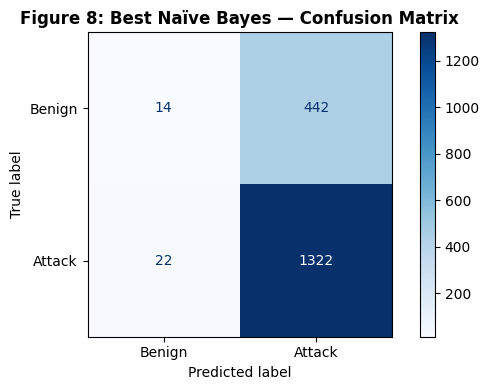

In [ ]:
# ── Confusion Matrix — Best NB ──
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_cls_test, y_pred_nb_best,
    display_labels=['Benign', 'Attack'], cmap='Blues', ax=ax
)
ax.set_title('Figure 8: Best Naïve Bayes — Confusion Matrix', fontweight='bold')
plt.tight_layout()

### 4B. Classification — Decision Tree

In [ ]:
# ── 4B.1 Baseline Decision Tree ──
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_cls_train, y_cls_train)

y_pred_dt_baseline = dt_baseline.predict(X_cls_test)
train_pred_dt_bl   = dt_baseline.predict(X_cls_train)

print('=== Baseline Decision Tree ===')
print(classification_report(y_cls_test, y_pred_dt_baseline,
                             target_names=['Benign', 'Attack']))
print(f'Train Acc: {accuracy_score(y_cls_train, train_pred_dt_bl):.4f}  '
      f'Test Acc:  {accuracy_score(y_cls_test, y_pred_dt_baseline):.4f}')

=== Baseline Decision Tree ===
              precision    recall  f1-score   support

      Benign       0.26      0.28      0.27       456
      Attack       0.75      0.73      0.74      1344

    accuracy                           0.62      1800
   macro avg       0.51      0.51      0.51      1800
weighted avg       0.63      0.62      0.62      1800

Train Acc: 1.0000  Test Acc:  0.6161


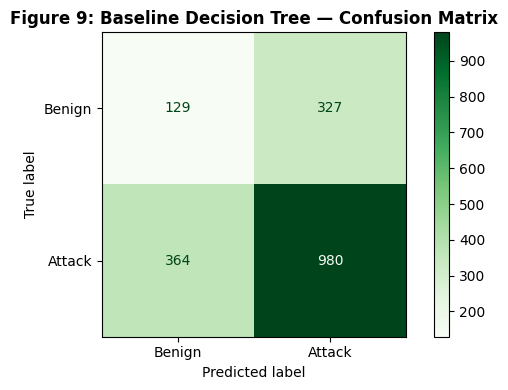

Accuracy: 0.6161


In [ ]:
# ── Confusion Matrix — Baseline DT ──
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_cls_test, y_pred_dt_baseline,
    display_labels=['Benign', 'Attack'], cmap='Greens', ax=ax
)
ax.set_title('Figure 9: Baseline Decision Tree — Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.savefig('fig9_dt_baseline_cm.png', dpi=150, bbox_inches='tight')
plt.show()
accuracy_b = accuracy_score(y_cls_test, y_pred_dt_baseline)
print(f"Accuracy: {accuracy_b:.4f}")

In [ ]:
# ── 4B.2 Improved Decision Tree — GridSearchCV + Stratified 10-Fold ──
param_grid_dt = {
    'max_depth':        [3, 5, 10, None],
    'min_samples_split':[2, 5, 10],
    'min_samples_leaf': [1, 5, 10, 20],
}

gs_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    cv=StratifiedKFold(10),
    scoring='accuracy',
    n_jobs=-1
)
gs_dt.fit(X_cls_train, y_cls_train)

print('Best params (DT):', gs_dt.best_params_)
print(f'Best CV accuracy: {gs_dt.best_score_:.4f}')

Best params (DT): {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.7524


In [ ]:
# ── 4B.3 Evaluate Best DT Model ──
dt_best = gs_dt.best_estimator_
y_pred_dt_best = dt_best.predict(X_cls_test)
train_pred_dt_best = dt_best.predict(X_cls_train)

print(f'=== Best Decision Tree {gs_dt.best_params_} ===')
print(classification_report(y_cls_test, y_pred_dt_best,
                             target_names=['Benign', 'Attack']))
print(f'Train Acc: {accuracy_score(y_cls_train, train_pred_dt_best):.4f}  '
      f'Test Acc:  {accuracy_score(y_cls_test, y_pred_dt_best):.4f}')

=== Best Decision Tree {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2} ===
              precision    recall  f1-score   support

      Benign       0.49      0.06      0.11       456
      Attack       0.75      0.98      0.85      1344

    accuracy                           0.75      1800
   macro avg       0.62      0.52      0.48      1800
weighted avg       0.69      0.75      0.66      1800

Train Acc: 0.7550  Test Acc:  0.7461


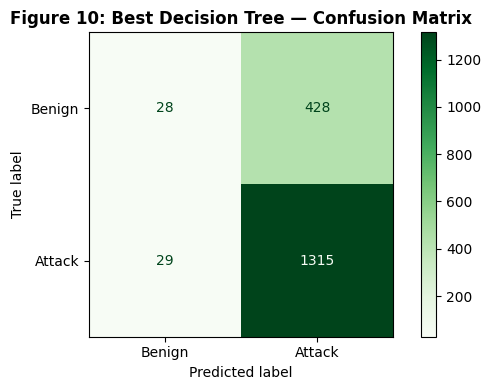

In [ ]:
# ── Confusion Matrix — Best DT ──
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_cls_test, y_pred_dt_best,
    display_labels=['Benign', 'Attack'], cmap='Greens', ax=ax
)
ax.set_title('Figure 10: Best Decision Tree — Confusion Matrix', fontweight='bold')
plt.tight_layout()


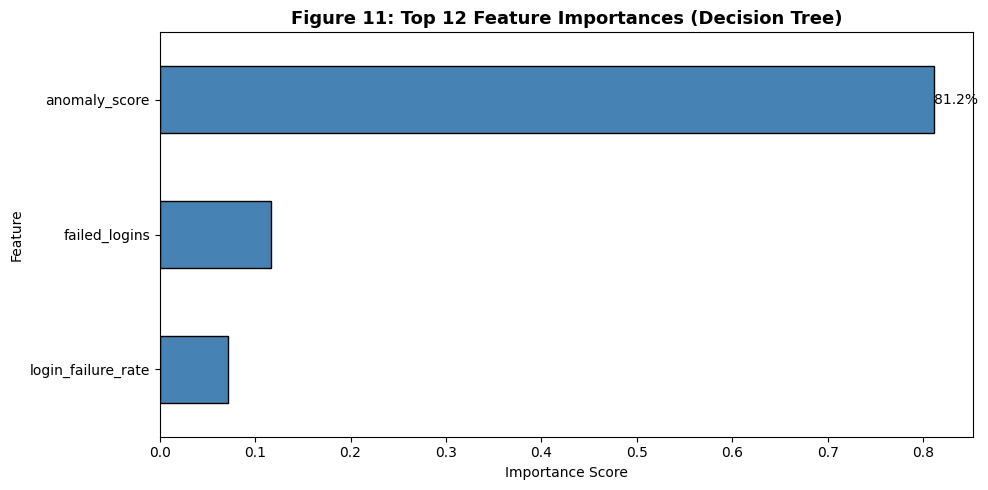

In [ ]:
# ── Feature Importance — Best DT ──
feat_imp = pd.Series(dt_best.feature_importances_, index=X_cls.columns).sort_values(ascending=True)
feat_imp = feat_imp[feat_imp > 0]

plt.figure(figsize=(10, 5))

ax = feat_imp.head(12).plot(kind='barh', color='steelblue', edgecolor='black')
for bar in ax.patches:
    width = bar.get_width()

y_pos = bar.get_y() + bar.get_height() / 2
plt.text(width, y_pos, f'{width*100:.1f}%', va='center', ha='left')
plt.title('Figure 11: Top 12 Feature Importances (Decision Tree)', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.xticks(rotation=0)
plt.tight_layout()

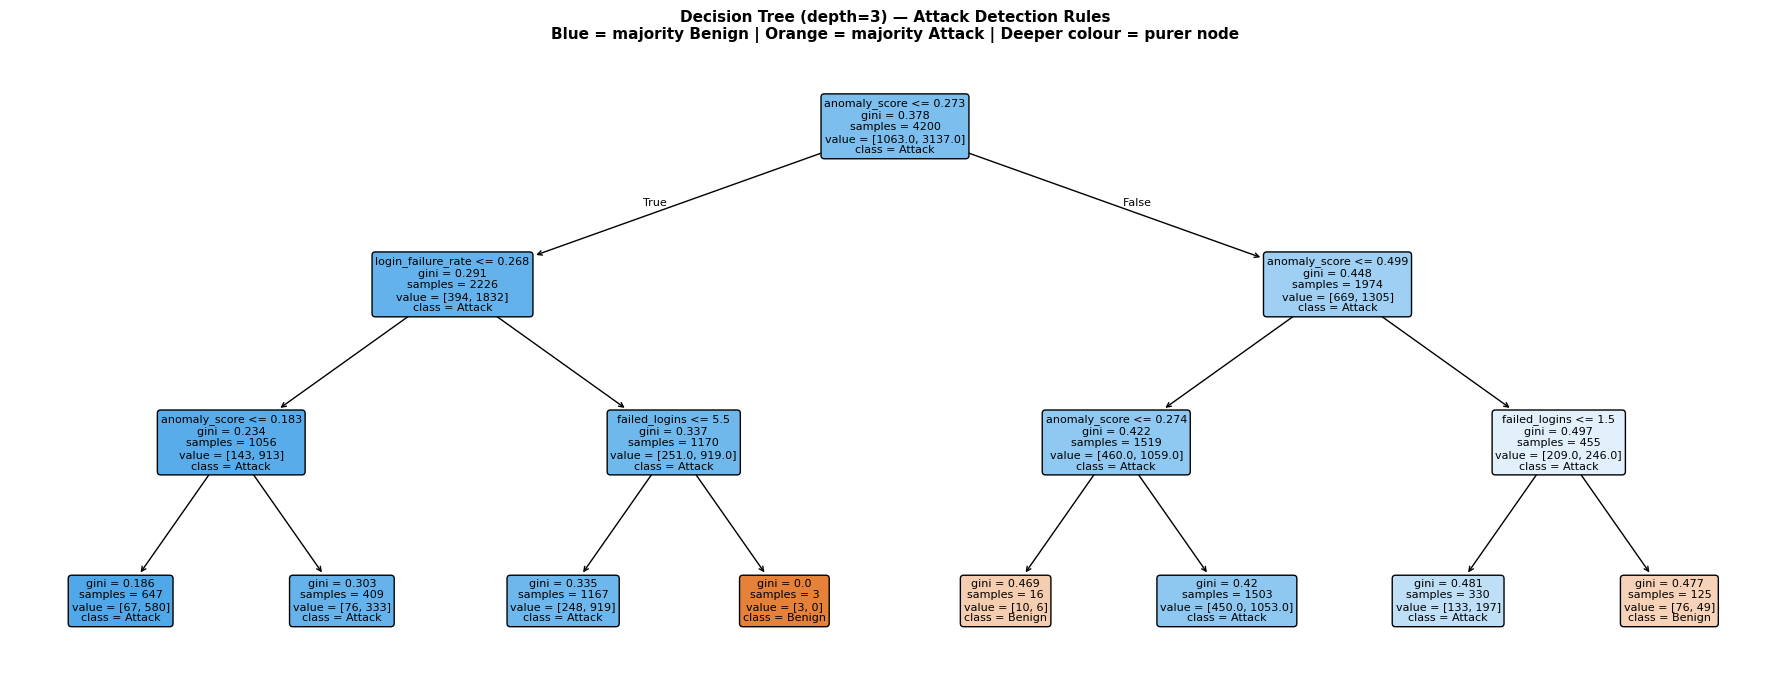

In [ ]:
from sklearn.tree import plot_tree

# Visualise the shallow tree
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(dt_best, feature_names=X_cls.columns, class_names=['Benign','Attack'],
          filled=True, rounded=True, fontsize=8, ax=ax, max_depth=3)
ax.set_title('Decision Tree (depth=3) — Attack Detection Rules\n'
             'Blue = majority Benign | Orange = majority Attack | Deeper colour = purer node',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 4C. Regression — Linear Regression & Decision Tree Regressor

In [ ]:
# ── 4C.1 Baseline Linear Regression ──
lr = LinearRegression()
lr.fit(X_reg_train_sc, y_reg_train)

y_pred_lr = lr.predict(X_reg_test_sc)

print('=== Baseline Linear Regression ===')
print(f'MAE:  {mean_absolute_error(y_reg_test, y_pred_lr):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_reg_test, y_pred_lr)):.4f}')
print(f'R²:   {r2_score(y_reg_test, y_pred_lr):.4f}')

=== Baseline Linear Regression ===
MAE:  9.7793
RMSE: 12.3144
R²:   0.4752


In [ ]:
# ── 4C.2 Decision Tree Regressor — Baseline ──
dtr_baseline = DecisionTreeRegressor(random_state=42)
dtr_baseline.fit(X_reg_train, y_reg_train)
y_pred_dtr_bl = dtr_baseline.predict(X_reg_test)

print('=== Baseline Decision Tree Regressor ===')
print(f'MAE:  {mean_absolute_error(y_reg_test, y_pred_dtr_bl):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_reg_test, y_pred_dtr_bl)):.4f}')
print(f'R²:   {r2_score(y_reg_test, y_pred_dtr_bl):.4f}')

=== Baseline Decision Tree Regressor ===
MAE:  14.9395
RMSE: 18.6265
R²:   -0.2007


In [ ]:
# ── 4C.3 Improved Decision Tree Regressor — GridSearchCV ──
param_grid_dtr = {
    'max_depth':        [3, 5, 10, None],
    'min_samples_split':[2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

gs_dtr = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid_dtr,
    cv=5, scoring='r2', n_jobs=-1
)
gs_dtr.fit(X_reg_train, y_reg_train)

print('Best DT Regressor params:', gs_dtr.best_params_)

y_pred_dtr_best = gs_dtr.best_estimator_.predict(X_reg_test)
print(f'MAE:  {mean_absolute_error(y_reg_test, y_pred_dtr_best):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_reg_test, y_pred_dtr_best)):.4f}')
print(f'R²:   {r2_score(y_reg_test, y_pred_dtr_best):.4f}')

Best DT Regressor params: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
MAE:  10.6479
RMSE: 13.4448
R²:   0.3744


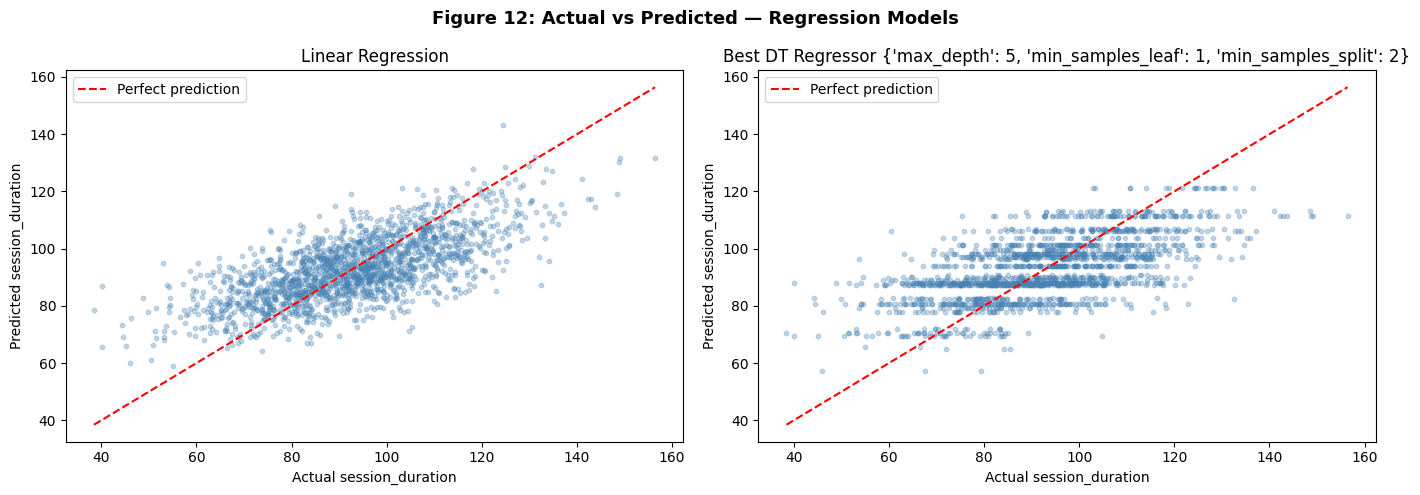

In [ ]:
# ── Actual vs Predicted Plot — Best DT Regressor ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title in [
    (axes[0], y_pred_lr,       'Linear Regression'),
    (axes[1], y_pred_dtr_best, f'Best DT Regressor {gs_dtr.best_params_}')
]:
    ax.scatter(y_reg_test, y_pred, alpha=0.3, color='steelblue', s=10)
    lims = [min(y_reg_test.min(), y_pred.min()), max(y_reg_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
    ax.set_xlabel('Actual session_duration')
    ax.set_ylabel('Predicted session_duration')
    ax.set_title(title)
    ax.legend()

plt.suptitle('Figure 12: Actual vs Predicted — Regression Models', fontsize=13, fontweight='bold')
plt.tight_layout()

---
## 5. Evaluation & Comparison

In [ ]:
# ── Classification Summary Table ──
def cls_metrics(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall':    round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1-Score':  round(f1_score(y_true, y_pred, zero_division=0), 4)
    }

cls_results = pd.DataFrame([
    cls_metrics(y_cls_test, y_pred_nb_baseline,  'Baseline Naïve Bayes'),
    cls_metrics(y_cls_test, y_pred_nb_best,      'Best Naïve Bayes (GridSearchCV)'),
    cls_metrics(y_cls_test, y_pred_dt_baseline,  'Baseline Decision Tree'),
    cls_metrics(y_cls_test, y_pred_dt_best,      'Best Decision Tree (GridSearchCV)'),
])
cls_results.set_index('Model', inplace=True)
print('=== Classification Model Comparison ===')
cls_results

=== Classification Model Comparison ===


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Baseline Naïve Bayes,0.5856,0.7990,0.5945,0.6817
Best Naïve Bayes (GridSearchCV),0.7422,0.7494,0.9836,0.8507
Baseline Decision Tree,0.6161,0.7498,0.7292,0.7393
Best Decision Tree (GridSearchCV),0.7461,0.7544,0.9784,0.8520


In [ ]:
# ── Regression Summary Table ──
def reg_metrics(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'MAE':  round(mean_absolute_error(y_true, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        'R²':   round(r2_score(y_true, y_pred), 4)
    }

reg_results = pd.DataFrame([
    reg_metrics(y_reg_test, y_pred_lr,       'Linear Regression'),
    reg_metrics(y_reg_test, y_pred_dtr_bl,   'Baseline DT Regressor'),
    reg_metrics(y_reg_test, y_pred_dtr_best, 'Best DT Regressor (GridSearchCV)'),
])
reg_results.set_index('Model', inplace=True)
print('=== Regression Model Comparison ===')
reg_results

=== Regression Model Comparison ===


,MAE,RMSE,R²
Model,,,
Linear Regression,9.7793,12.3144,0.4752
Baseline DT Regressor,14.9395,18.6265,-0.2007
Best DT Regressor (GridSearchCV),10.6479,13.4448,0.3744


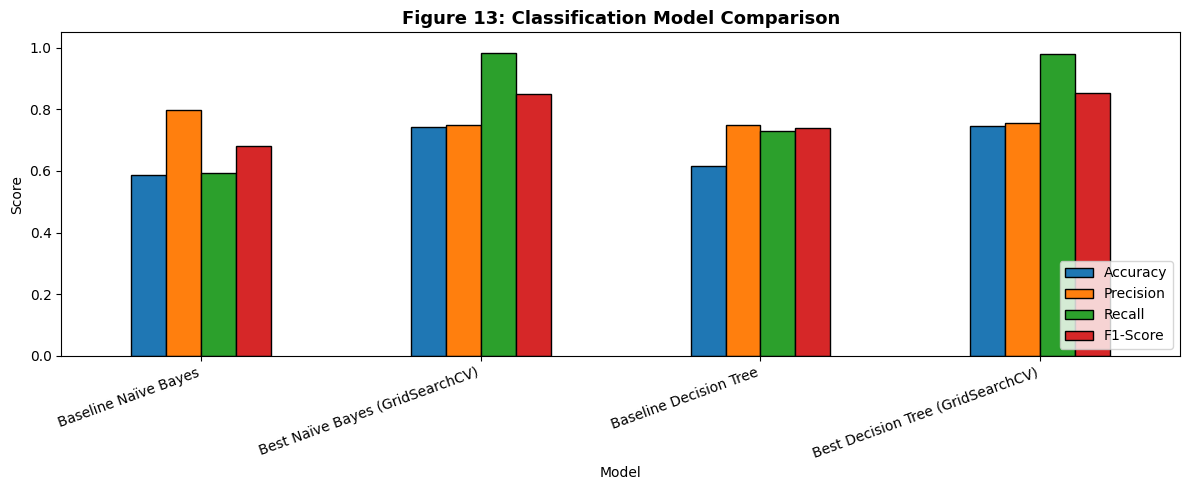

In [ ]:
# ── Bar Chart — Classification Metrics ──
cls_results.plot(kind='bar', figsize=(12, 5), edgecolor='black')
plt.title('Figure 13: Classification Model Comparison', fontsize=13, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()